In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 04. The Big Three era

The Big Three are Roger Federer, Rafael Nadal, and Novak Djokovic. They are grouped together because, for most of this window, at least one of them won almost every Slam. This chapter counts their Slam matches and titles, compares them with the rest of the field, and counts their matches against each other.

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## Titles first

From 2000 to 2019 there were 80 Slam finals in this data. The Big Three won 55 of them. All 55 came from 2003 onward, so from 2003 to 2019 they won 55 of 68 Slams. Before that, in 2000 to 2002, they won none of the 12. The era did not start in 2000. It started when Federer won Wimbledon in 2003.

In [3]:
df = pd.read_csv(f'{PROC}/slam_player_matches.csv')
fin = pd.read_csv(f'{PROC}/slam_finals_2000_2019.csv')
big_ids = ['atp_103819', 'atp_104745', 'atp_104925']
print(fin.groupby('name').size().sort_values(ascending=False).head(10))
print('Big Three titles 2000 to 2019:', fin.player_id.isin(big_ids).sum(), 'of', len(fin))
print('Big Three titles 2003 to 2019:', fin[(fin.year >= 2003)].player_id.isin(big_ids).sum(), 'of', len(fin[fin.year >= 2003]))
for pid, name in [('atp_103819', 'Federer'), ('atp_104745', 'Nadal'), ('atp_104925', 'Djokovic')]:
    g = df[df.player_id == pid]
    print(f"{name}: {len(g)} Slam matches, {int(g.winner.sum())} wins, win rate {g.winner.mean():.3f}")

name
Roger Federer      20
Rafael Nadal       19
Novak Djokovic     16
Andre Agassi        3
Stan Wawrinka       3
Andy Murray         3
Pete Sampras        2
Gustavo Kuerten     2
Lleyton Hewitt      2
Marat Safin         2
dtype: int64
Big Three titles 2000 to 2019: 55 of 80
Big Three titles 2003 to 2019: 55 of 68
Federer: 413 Slam matches, 357 wins, win rate 0.864
Nadal: 309 Slam matches, 271 wins, win rate 0.877
Djokovic: 322 Slam matches, 279 wins, win rate 0.866


## Chart: Big Three Slam titles by player, 2000 to 2019.

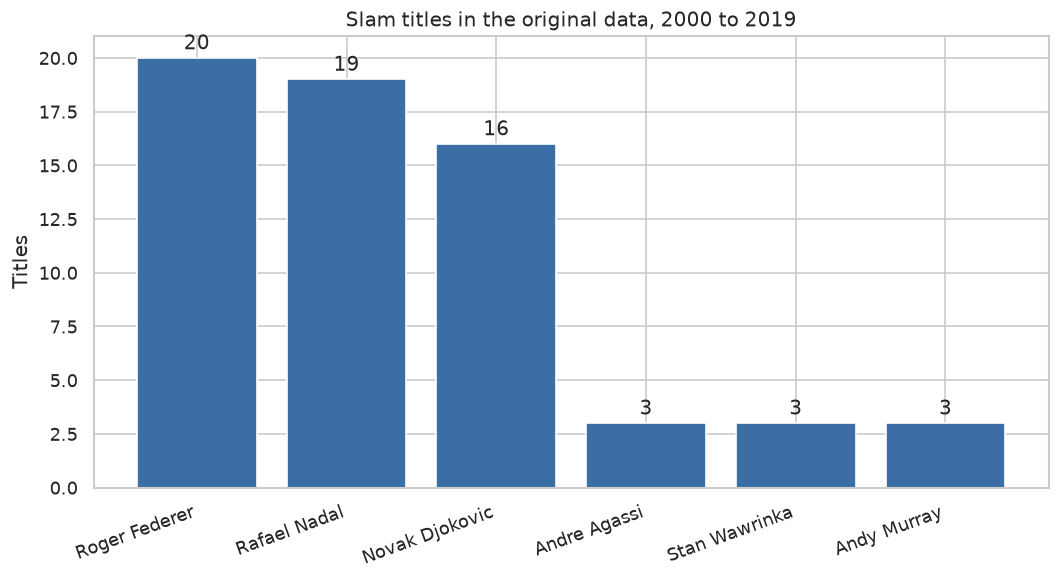

In [4]:
titles = fin.groupby('name').size().sort_values(ascending=False).head(6)
plt.figure(figsize=(9, 5)); plt.bar(titles.index, titles.values, color='#3a6ea5')
plt.title('Slam titles in the original data, 2000 to 2019'); plt.ylabel('Titles'); plt.xticks(rotation=20, ha='right')
for i, v in enumerate(titles.values): plt.text(i, v + 0.4, str(v), ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/04_slam_titles_by_player.png'); plt.show()

## Chart: Big Three Slam matches per year. The lines show who was active and winning, year by year.

player  Djokovic  Federer  Nadal
year                            
2010          23       23     26
2011          26       24     26
2012          27       22     16
2013          27       17     15
2014          25       23     18
2015          28       22     15
2016          23       12      7
2017          12       19     25
2018          23       16     24
2019          23       22     26


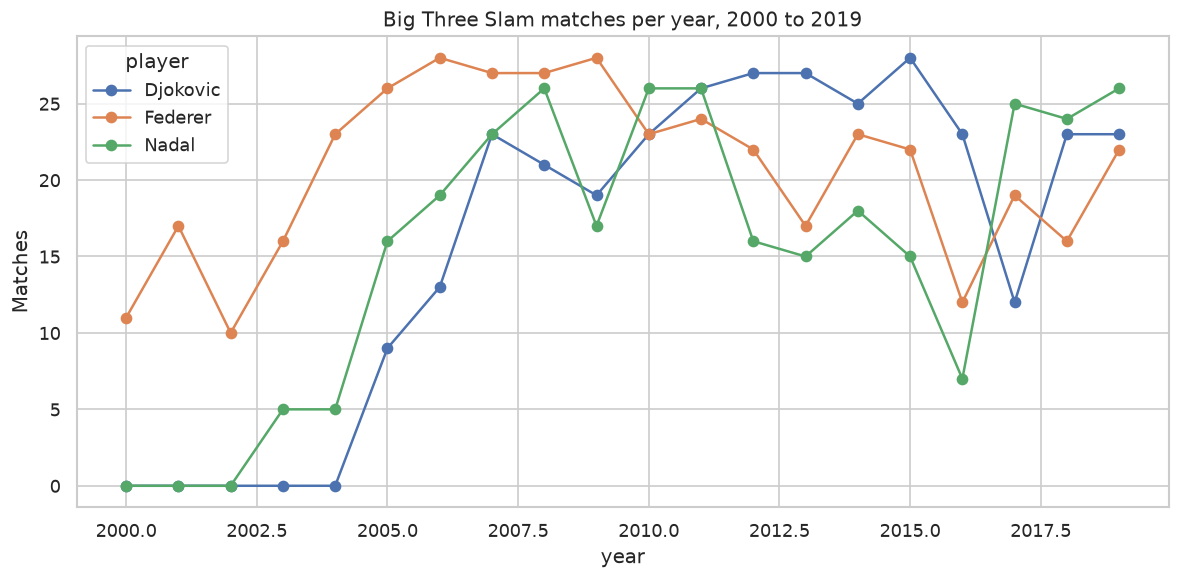

In [5]:
big = df[df.player_id.isin(big_ids)].copy()
big['player'] = big.player_id.map({'atp_103819': 'Federer', 'atp_104745': 'Nadal', 'atp_104925': 'Djokovic'})
yr = big.groupby(['year', 'player']).size().unstack(fill_value=0)
print(yr.tail(10))
yr.plot(figsize=(10, 5), marker='o')
plt.title('Big Three Slam matches per year, 2000 to 2019'); plt.ylabel('Matches')
plt.tight_layout(); plt.savefig(f'{CH}/04_big3_matches_per_year.png'); plt.show()

## Against each other

In this Slam data, Big Three players met each other 45 times. Nadal won 19 of those matches, Djokovic 16, and Federer 10. Head to head, Nadal beat Federer 10 times and lost 4, Djokovic beat Federer 10 times and lost 6, and Nadal beat Djokovic 9 times and lost 6. These are Slam matches only, not their full tour meetings, so do not compare them with career head to head totals from other sources.

In [6]:
stats = pd.read_csv('../data/raw/Stats.csv')
pairs = stats.groupby('match_id')['player_id'].apply(list)
both = [mid for mid, ids in pairs.items() if sum(i in big_ids for i in ids) == 2]
print('Big Three versus Big Three Slam matches:', len(both))
bb = stats[stats.match_id.isin(both)]
win = bb[bb.winner == True].merge(pd.read_csv('../data/raw/Player.csv'), on='player_id')
print(win.groupby('name').size())
import collections
c = collections.Counter()
names = {'atp_103819': 'Federer', 'atp_104745': 'Nadal', 'atp_104925': 'Djokovic'}
for mid in both:
    rows = bb[bb.match_id == mid]
    w = rows[rows.winner == True].iloc[0]; l = rows[rows.winner == False].iloc[0]
    c[(names[w.player_id], names[l.player_id])] += 1
for k, v in sorted(c.items()): print(k, v)

Big Three versus Big Three Slam matches: 45
name
Novak Djokovic    16
Rafael Nadal      19
Roger Federer     10
dtype: int64


('Djokovic', 'Federer') 10
('Djokovic', 'Nadal') 6
('Federer', 'Djokovic') 6
('Federer', 'Nadal') 4
('Nadal', 'Djokovic') 9
('Nadal', 'Federer') 10


## Chart: who won the 45 Big Three Slam meetings.

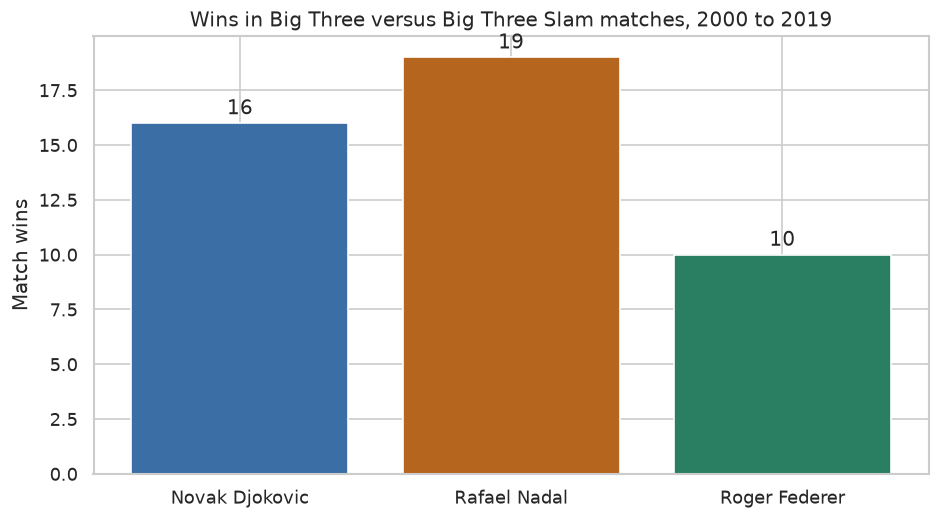

In [7]:
vals = win.groupby('name').size()
plt.figure(figsize=(8, 4.5)); plt.bar(vals.index, vals.values, color=['#3a6ea5', '#b5651d', '#2a7f62'])
plt.title('Wins in Big Three versus Big Three Slam matches, 2000 to 2019'); plt.ylabel('Match wins')
for i, v in enumerate(vals.values): plt.text(i, v + 0.4, str(v), ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/04_big3_head_to_head.png'); plt.show()